# TD : Multiple linear regression

Christelle Gonindard & Matthias Grenié

**This tutorial has two objectives:**

1. Identify the $X_i$ quantitative variables that have an influence on the $Y$ quantitative variable (measurement).
2. If linear correlation exists, find a linear equation that predicts Y from X.


## 1. Presentation of the study

This is a study of intraoperative mean arterial pressure in patients with obstructive sleep apnea undergoing weight loss (bariatric) surgery. 

Participants were 281 adult patients diagnosed with obstructive sleep apnea within two years prior to their bariatric surgery. In addition to mean arterial pressure, the data set includes information on demographic characteristics, nocturnal oxygenation status, comorbidities, type and duration of surgery, vasopressors and heart rate. Data are cleaned and contain some missing data. There are no outliers or data problems. 

**Background**

Sleep apnea, literally “no breathing”, occurs during sleep when breathing becomes very shallow or stops briefly.  Sleep apnea episodes generally last 20 to 40 seconds, and may occur several times a night in some people. There are different types of sleep apnea, including obstructive sleep apnea (OSA), which is the topic of this data set. OSA has physical causes; it occurs when something partially or completely blocks the upper airway during sleep. OSA is generally associated with a reduction in blood oxygen saturation (Sao2). Approximately 30% of the general population suffers from OSA.

Obstructive sleep apnea is characterized by specific events and their severity. OSA events are of two types: apnea, characterized by a complete cessation of airflow for at least 10 seconds, or hypopnea, in which airflow decreases by 50% for 10 seconds, or decreases by 30% if there is an associated decrease in oxygen saturation or sleep arousal. The severity of sleep apnea corresponds to the frequency of events per hour, and is assessed using the apnea-hypopnea index (AHI). An AHI of less than 5 is considered normal. An AHI of 5 to 14 is mild, 15 to 29 is moderate, and 30 or more events per hour characterizes severe sleep apnea.

Due to OSA, nocturnal oxygenation levels are often lower than normal. Two common measures are the percentage of total sleep time spent at a Sao2 below 90% and the minimum nocturnal Sao2 indicated in polysomnography reports.  
OSA is of concern due to its relationship with cardiovascular disease, with a diagnosis of moderate to severe disease (AHI ≥ 15) having been identified as an independent risk factor for all-cause and cardiovascular mortality. OSA patients exhibit a chronic increase in sympathetic adrenergic activity (a system involved in maintaining homeostasis), which is considered to be one of the main mechanisms for the development of cardiovascular health problems in this population. It is hypothesized that such hemodynamic instability increases the risk of intraoperative and/or postoperative morbidity in OSA patients undergoing surgery.

**Variables:**

- `Age`: patient's age,
- `BMI`: Body Mass Index,
- `Duration_of_Surg`: duration of surgery in hours,
- `TWA.MAP`: average blood pressure during surgery,
- `TWA.HR`: average heart rate during surgery ,
- `Sleeptime`: time spent with Sao2 < 90% (% of total sleep time),
- `Morphine`: morphine dose (mg).
   
**Study objective:**

We would like to be able to predict the Sao2 nocture minimum as a function of the proposed variables. 

The source of these data is the study by Turan et al.

> “Relationship between Chronic Intermittent Hypoxia and Intraoperative Mean Arterial Pressure in Obstructive Sleep Apnea Patients Having Laparoscopic Bariatric Surgery”. Anesthesiology 2015; 122: 64-71.

## 2. Data analysis

### 2.1. Descriptive studies of data and relationships between variables

The data are contained in the file `TD12_hypoxia.csv` in the `data/` folder.

In [1]:
# Loading libraries useful for the study

library(ggplot2)
library(GGally)

Warning message:
"le package 'ggplot2' a été compilé avec la version R 4.3.3"
Warning message:
"le package 'GGally' a été compilé avec la version R 4.3.3"
Registered S3 method overwritten by 'GGally':
  method from   
  +.gg   ggplot2



In [2]:
# Read data file, name it hypoxia
hypoxia = read.table("data/TD12_hypoxia.txt", header = TRUE)


# Display statistical summary of data
summary(hypoxia)

      Age             BMI          Sleeptime         Min.Sao2     
 Min.   :20.65   Min.   :22.20   Min.   : 2.203   Min.   : 48.04  
 1st Qu.:40.26   1st Qu.:41.75   1st Qu.:34.796   1st Qu.: 70.99  
 Median :48.23   Median :46.21   Median :45.009   Median : 78.83  
 Mean   :47.55   Mean   :46.85   Mean   :45.361   Mean   : 78.76  
 3rd Qu.:54.95   3rd Qu.:51.66   3rd Qu.:55.052   3rd Qu.: 86.75  
 Max.   :80.09   Max.   :72.00   Max.   :89.332   Max.   :107.22  
 Duration_of_Surg    Morphine        TWA.MAP           TWA.HR      
 Min.   :3.980    Min.   :28.63   Min.   : 65.07   Min.   : 54.72  
 1st Qu.:4.145    1st Qu.:43.05   1st Qu.: 81.39   1st Qu.: 69.05  
 Median :4.216    Median :45.64   Median : 88.97   Median : 75.92  
 Mean   :4.211    Mean   :45.66   Mean   : 89.09   Mean   : 76.12  
 3rd Qu.:4.279    3rd Qu.:48.35   3rd Qu.: 96.12   3rd Qu.: 83.11  
 Max.   :4.486    Max.   :60.73   Max.   :125.17   Max.   :109.50  

### 2.2. Correlation between explanatory variables

,Age,BMI,Sleeptime,Min.Sao2,Duration_of_Surg,Morphine,TWA.MAP,TWA.HR
Age,1.00000000,0.48958900,0.56534334,-0.67000,0.37765720,-0.03375227,0.03808482,-0.3764270
BMI,0.48958900,1.00000000,0.80405004,-0.85000,0.45978639,-0.07735469,-0.03420647,-0.1223763
Sleeptime,0.56534334,0.80405004,1.00000000,-0.90000,0.50574403,0.01738417,-0.02143124,-0.1004486
Min.Sao2,-0.67000000,-0.85000000,-0.90000000,1.00000,-0.59000000,-0.00002000,0.01000000,0.1800000
Duration_of_Surg,0.37765720,0.45978639,0.50574403,-0.59000,1.00000000,-0.01404979,0.01916434,-0.1183908
Morphine,-0.03375227,-0.07735469,0.01738417,-0.00002,-0.01404979,1.00000000,0.05889589,0.1370681
TWA.MAP,0.03808482,-0.03420647,-0.02143124,0.01000,0.01916434,0.05889589,1.00000000,0.1695057
TWA.HR,-0.37642701,-0.12237627,-0.10044857,0.18000,-0.11839078,0.13706806,0.16950571,1.0000000


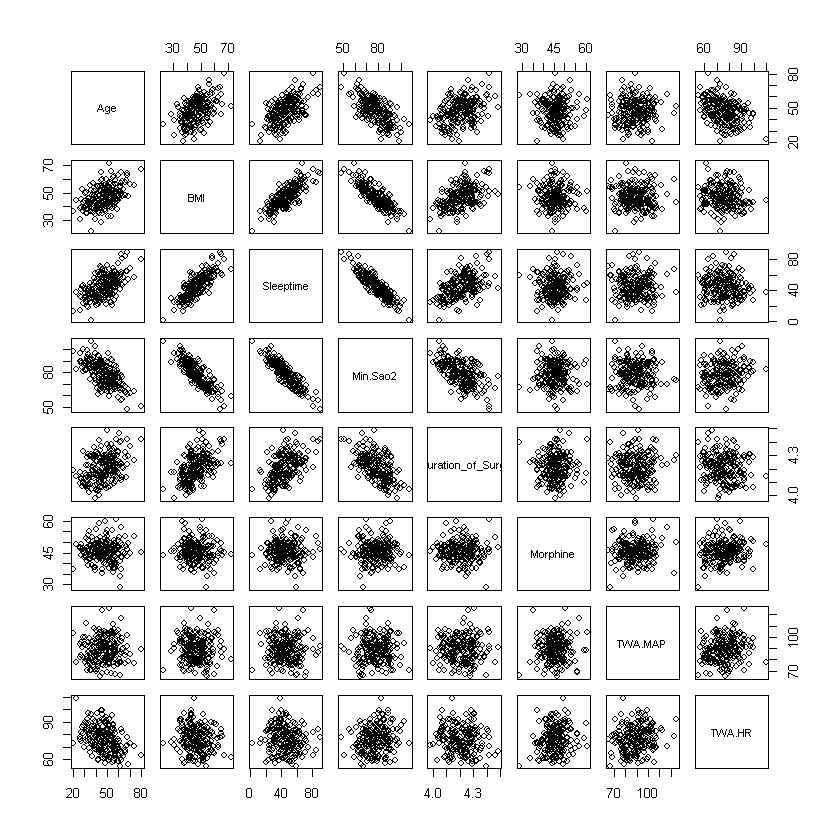

In [3]:
# Plots
plot(hypoxia)

# Correlation
cor(hypoxia)



In [4]:
# Normal distribution of data



### 2.3 Data partitioning

Before we start training our machine learning model, we need to divide our dataset into training and test subsets. The training dataset is used to learn or “train” our machine learning model to make predictions with our data, while the test dataset is used to test our model on data it hasn't seen to see how it performs.


We'll create a train/test partition with `createDataPartition()` from the `caret` package. This will divide our
data by random sampling and give us the sampled index.

In [5]:
# Loading the library
library(caret)

# Let's set the randomness so that everyone gets the same result

set.seed(123)

train_index <- createDataPartition(y = hypoxia$Min.Sao2, # y = dependent variable.
                                   p = .7, # to specify data distribution 70% & 30%.
                                  list = FALSE, # results are in the form of a matrix
                                  times = 1) # Set the number of partitions to be created to 1.

#train_index

Warning message:
"le package 'caret' a été compilé avec la version R 4.3.2"
Le chargement a nécessité le package : lattice

Warning message:
"le package 'lattice' a été compilé avec la version R 4.3.3"


Now we can divide our data into training and test data using the random sample `train_index` we've just trained.

In [7]:
# Use train_index from hypoxie data to create train_data.
train_data <- hypoxia[train_index,] 

# Use anything not in train_index to create test_data.
test_data <- hypoxia[-train_index,] 


# Dimension of training table
dim(train_data)
# Dimension of test data
dim(test_data)

head(train_data)

[1] 140   8

[1] 60  8

,Age,BMI,Sleeptime,Min.Sao2,Duration_of_Surg,Morphine,TWA.MAP,TWA.HR
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
5,35.19395,55.25255,48.70835,74.42234,4.153194,48.16802,81.65388,65.62081
8,45.70732,45.76192,27.62975,87.10145,4.140070,45.60148,68.25916,61.38572
9,49.51501,47.09051,46.58408,75.89814,4.199232,47.51222,80.60802,70.21089
10,49.91774,42.74281,35.08020,85.60078,4.092075,48.54075,83.83200,62.16872
11,53.65230,49.47198,51.86975,71.01055,4.253067,43.71054,94.01745,81.38550
12,59.47040,47.40076,46.60030,75.90872,4.163796,44.43875,101.96142,76.01584


## 3. Building a model with all variables from training data 


### 3.1 Line calculation

We will first build the model with the set of explanatory variables retained from the previous step. The variable Y = Min.Sao2 will be predicted from the set of explanatory variables selected above:

$$Min.Sao2=a_1 \times Age+a_2 \times BMI + a_3 \times Sleeptime +a_4 \times Duration_of\_Surg
+ a_5 \times Morphine + a_6 \times TWA.MAP + a_7 \times TWA.HR +b$$

which amounts to estimating the values of the parameters
$a_1$, $a_2$, $a_3$, $a_4$, $a_5$, $a_6$, $a_7$, $b$.

*Calculate the model equation and comment*.

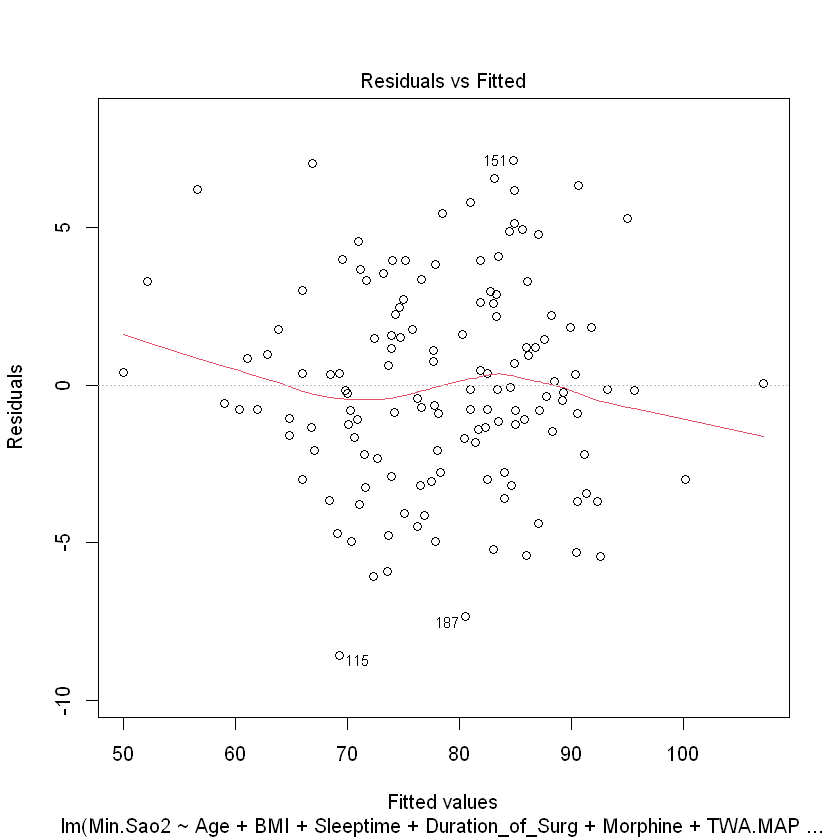

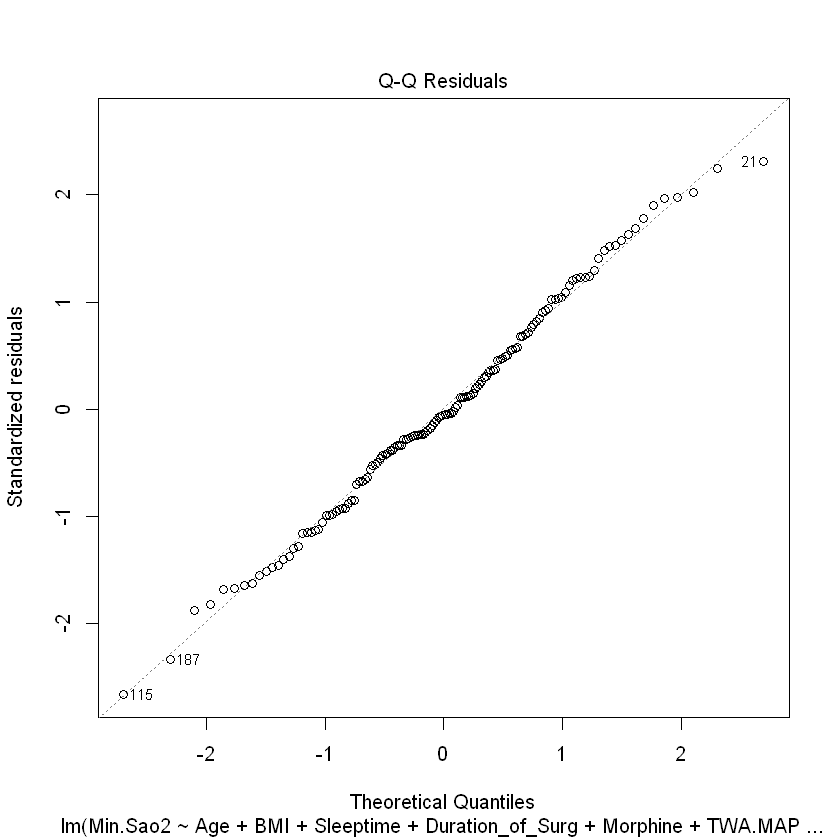

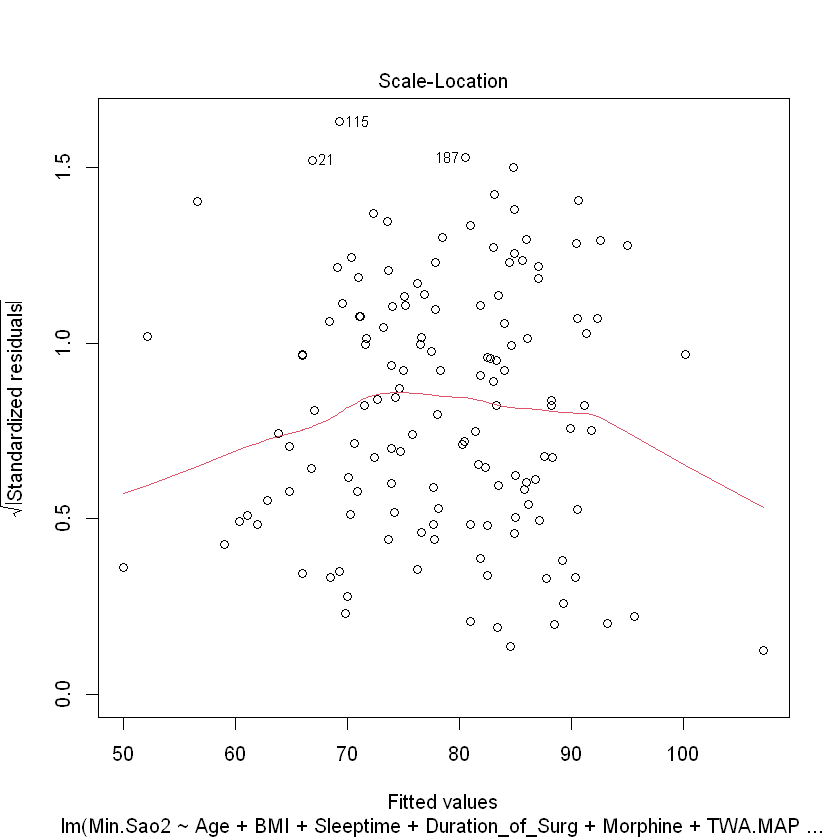

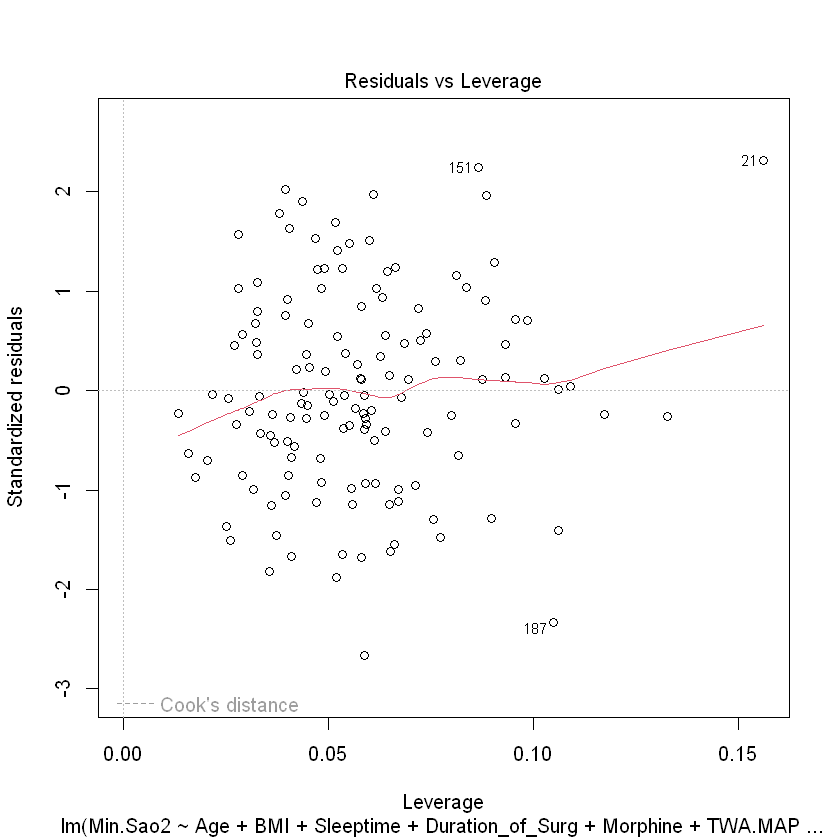

In [10]:
# Calculation of the complete model
model = lm(Min.Sao2 ~ Age + BMI + Sleeptime + Duration_of_Surg + Morphine + TWA.MAP + TWA.HR, data = train_data)

# Display result

plot(model)

### 3.2 Model validation


**1. Test of the influence of $X_i$ variables on Y**.


**Test on slope: Wald's test**

*Perform Wald test and conclude*.

In [11]:
summary(model)


Call:
lm(formula = Min.Sao2 ~ Age + BMI + Sleeptime + Duration_of_Surg + 
    Morphine + TWA.MAP + TWA.HR, data = train_data)

Residuals:
    Min      1Q  Median      3Q     Max 
-8.5655 -2.1115 -0.1686  2.2109  7.1252 

Coefficients:
                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)      183.491282  14.302633  12.829  < 2e-16 ***
Age               -0.201068   0.033974  -5.918 2.65e-08 ***
BMI               -0.419167   0.061841  -6.778 3.68e-10 ***
Sleeptime         -0.312611   0.037612  -8.312 1.00e-13 ***
Duration_of_Surg -13.960131   3.391711  -4.116 6.75e-05 ***
Morphine          -0.049262   0.061945  -0.795    0.428    
TWA.MAP            0.009252   0.025956   0.356    0.722    
TWA.HR            -0.014739   0.029877  -0.493    0.623    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 3.319 on 132 degrees of freedom
Multiple R-squared:  0.8974,	Adjusted R-squared:  0.8919 
F-statistic: 164.9 on 7 and 132 DF,  p-va

**Conclusion** : 

**2. Goodness of fit: Coefficient of determination $R^2$ (squared correlation coefficient)**.

Calculate $R^2$, perform test and conclude

In [12]:
# R2 value 
summary(model)$r.squared

# Variance distribution


[1] 0.8973812

**3. Residuals** study

Draw the graph representing the residuals and conclude

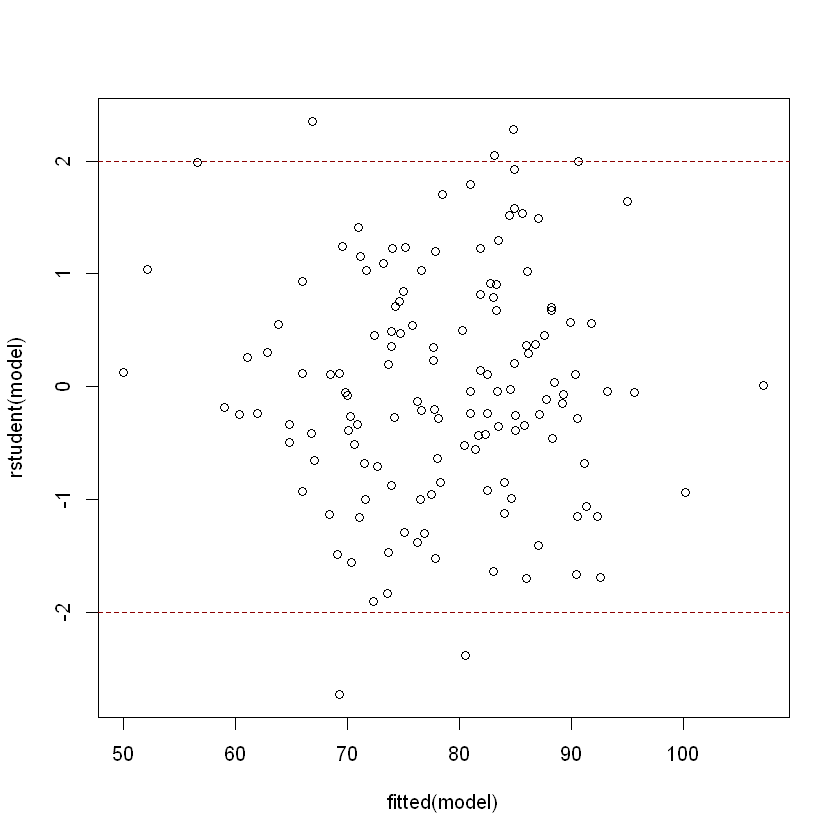

In [15]:
# Plot residuals
plot(fitted(model), rstudent(model))
abline(h = 2, col = "darkred", lty = 2)
abline(h = -2, col = "darkred", lty = 2)

**Conclusion**

**3. Cross-validation using test data** We will predict the data contained in the test_data from our model.

We will predict the data contained in test_data from our model

In [21]:
# Calculate predictions from test dataset
test_pred = predict(model, newdata = test_data)
dim(test_data)

# Display predicted sample size
length(test_pred)


[1] 60  8

[1] 60

*i) Evaluation based on the RMSE*.

$$RMSE = \sqrt{\frac{\sum(\hat{y}-y_i)^2}{n}} $$

This index provides an indication of the dispersion or variability of prediction quality.

In [22]:
### Model quality based on new data

# calculate RMSE

# calculate mean of true values (test_data$Min.Sao2)
mean_true = mean(test_data$Min.Sao2)

sqrt(sum((mean_true - test_pred)^2)/60)

[1] 9.668164

*ii) The coefficient of determination R2*.

[1] 0.8314583

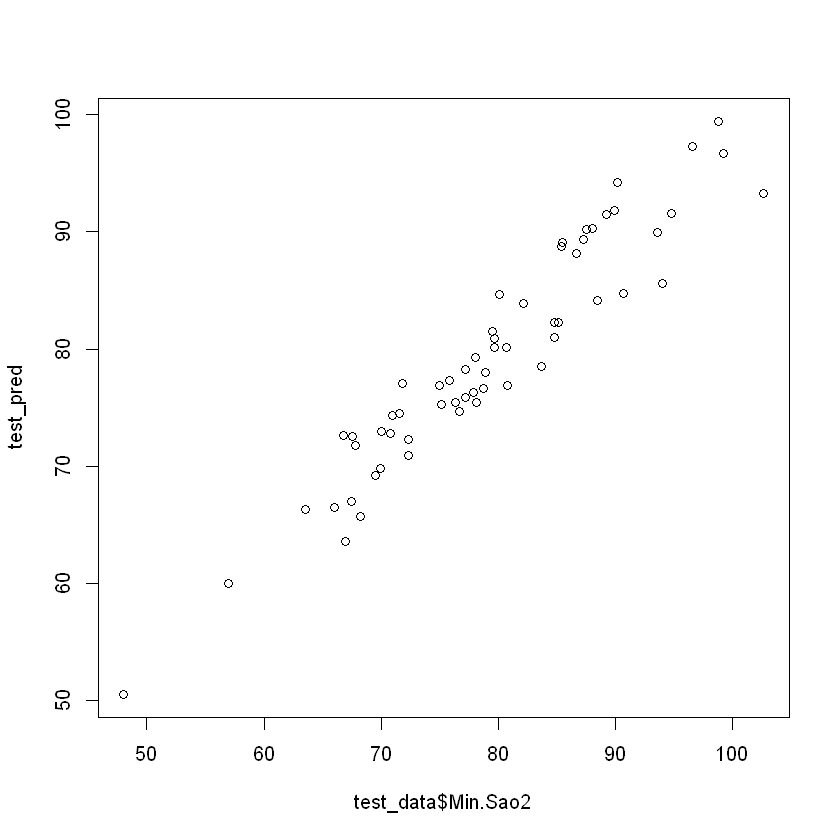

In [24]:
# Plot the graph representing predictions versus reality
plot(test_data$Min.Sao2, test_pred)

# Display R²
# R2 = variance explained by the model / total variance of data

sum((mean_true - test_pred)^2) / sum((test_data$Min.Sao2- mean_true)^2)

## 4. study of different models

We'll now compare different models to see their performances

In [9]:
##### Model without TWA.HR


# Model calculation 

# Model validation 

#i) Wald test

# ii) R2

# iii) Residuals


# iV) Cross-validation 

# RMSE

# R2


In [10]:
# Model without TWA.HR and Morphine


# Model calculation 

# Model validation 

#i) Wald test

# ii) R2

# iii) Residuals


# iV) Cross-validation 

# RMSE

# R2

In [11]:
# Model without TWA.HR, without Morphine and without TWA.MAP 


# Model calculation 

# Model validation 

#i) Wald test

# ii) R2

# iii) Residuals


# iV) Cross-validation 

# RMSE

# R2

In [12]:
# Model without TWA.HR, without Morphine, without TWA.MAP and, for example, without BMI


# Model calculation 

# Model validation 

#i) Wald test

# ii) R2

# iii) Residuals


# iV) Cross-validation 

# RMSE

# R2

In [13]:
# Model without TWA.HR, without Morphine, without TWA.MAP and for example without BMI and sleeptime


# Model calculation 

# Model validation 

#i) Wald test

# ii) R2

# iii) Residuals


# iV) Cross-validation 

# RMSE

# R2

In [68]:
# Model without TWA.HR + Morphine + BMI + Duration_of_Surg


# Model calculation 

# Model validation 

#i) Wald test

# ii) R2

# iii) Residuals


# iV) Cross-validation 

# RMSE

# R2

In [14]:
# Correct model with Sleeptime because most correlated with Min.Sao2


# Model calculation 

# Model validation 

#i) Wald test

# ii) R2

# iii) Residuals


# iV) Cross-validation 

# RMSE

# R2

## 5. Final choice of model

In view of the results you have obtained above, conclude and discuss.

## 6. Additional training exercise


The dataset is `TD12_heart_stroke.txt` in the `data/`.

The data proposed in this exercise show the death rate from heart attack for men aged 55 to 59 in different countries.
The variables are as follows:
- `country`: country name;
- `heart_strokes_death`: 100 [log(number of heart attack deaths per 100,000 men aged 55 to 59)
years) -2] ;
- `telephones`: telephones per thousand inhabitants ;
- `fat`: fat calories as a percentage of total calories;
- `animal_calories`: calories from animal protein as a percentage of total calories.

This study has two objectives:
- to identify the factors likely to influence heart disease
- to develop a method that predicts the death rate in a country as a function of the influencing factors identified in the previous step. 

Carry out this study at the 1% threshold. 